# Forest mapping and forest-loss detection, Ariquemes 2018 → 2022

End to end on real data: Sentinel-2 L1C dry-season composites (2018, 2022) and Hansen GFC labels, prepared by
`scripts/download_data.py`, `make_labels.py` and `make_tiles.py` (see the [README](../README.md)). The logic lives in
[`src/deforest/experiment.py`](../src/deforest/experiment.py), which `scripts/train.py` and `scripts/evaluate.py` also use;
this notebook orchestrates it and adds the figures.

1. Data loading and visual checks · 2. Baselines (NDVI threshold, random forest) · 3. U-Net (ImageNet vs random init) ·
4. Test-tile forest-mask metrics · 5. Change detection vs Hansen (differencing and direct models) · 6. Area lost ·
7. Error analysis · 8. PRODES check and limitations

Set `FAST_DEV_RUN=1` in the environment for a quick CPU smoke run (1 epoch, tiny RF). It writes to `outputs/fast_dev/`, never to `reports/`.

In [1]:
import json, os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path(os.environ.get("REPO_ROOT", Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
os.chdir(ROOT)
from deforest import baselines, change, experiment, prodes, viz
from deforest.config import load_config

FAST_DEV_RUN = os.environ.get("FAST_DEV_RUN", "0") == "1"
plt.rcParams["figure.dpi"] = 60  # keep the committed notebook small; saved figures set their own dpi
cfg = load_config("configs/ariquemes.yaml")
ucfg = load_config("configs/unet.yaml")
C = dict(ucfg.change)
N_BOOT = ucfg.fast_dev_run.bootstrap if FAST_DEV_RUN else C["bootstrap"]
SEED = ucfg.seed
OUT = Path("outputs/fast_dev") if FAST_DEV_RUN else Path(".")
METRICS, FIGS, MODELS = OUT / "reports/metrics", OUT / "reports/figures", OUT / "outputs/models"
for d in (METRICS, FIGS, MODELS):
    d.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cpu" if FAST_DEV_RUN or not torch.cuda.is_available() else "cuda")
print(f"FAST_DEV_RUN={FAST_DEV_RUN} device={DEVICE} torch={torch.__version__}",
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

def save_json(obj, name):
    (METRICS / name).write_text(json.dumps(obj, indent=2))
    print("wrote", METRICS / name)

def train(only):
    out = experiment.train_all(B, ucfg, MODELS, DEVICE, fast=FAST_DEV_RUN, only=only)
    experiment.write_train_metrics(out, METRICS, DEVICE)
    return out

FAST_DEV_RUN=False device=cuda torch=2.11.0+cu128 NVIDIA GeForce RTX 5080


## 1. Data loading and visual checks

In [2]:
B = experiment.load_bundle(cfg)
Y1, Y2 = B.years
SIZE, TILES, img, forest = B.size, B.tiles, B.img, B.forest
print({k: len(v) for k, v in TILES.items()}, "tiles of", SIZE, "px; pixel area",
      experiment.metrics.pixel_area_ha(B.transform), "ha; image", img[Y1].shape, img[Y1].dtype)
pd.DataFrame(json.loads(Path("reports/metrics/split.json").read_text())["test"]["stats"], index=["test"])

{'train': 47, 'val': 8, 'test': 9} tiles of 256 px; pixel area 0.01 ha; image (6, 2213, 2190) uint16


,n_tiles,valid_px,forest_frac_2018,forest_frac_2022,loss_frac_2019_2022,loss_px_2019_2022
test,9,589824,0.404,0.3842,0.0198,11680


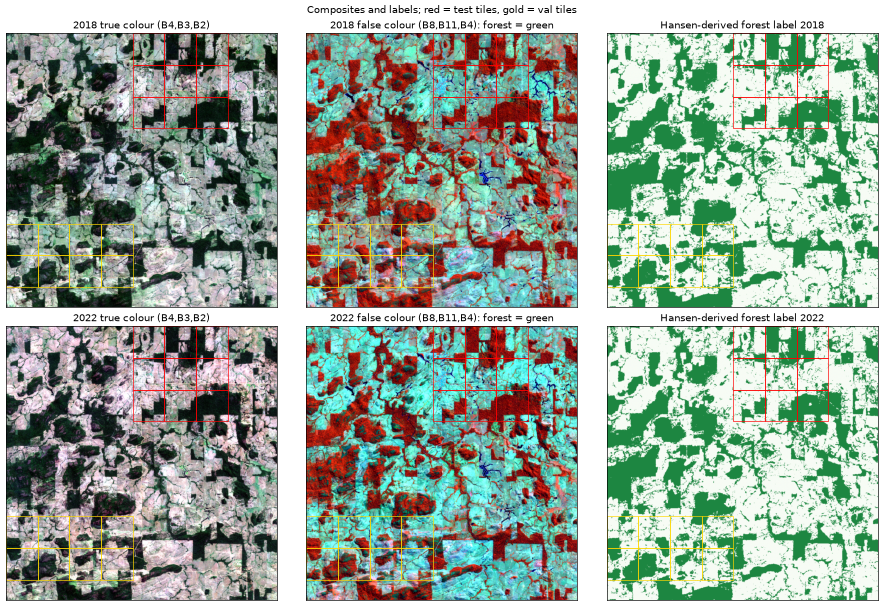

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(15, 10), layout="constrained")
for i, y in enumerate(B.years):
    ax[i, 0].imshow(viz.rgb(img[y], ref=img[Y1])); ax[i, 0].set_title(f"{y} true colour (B4,B3,B2)")
    ax[i, 1].imshow(viz.rgb(img[y], bands=("B8", "B11", "B4"), ref=img[Y1])); ax[i, 1].set_title(f"{y} false colour (B8,B11,B4): forest = green")
    ax[i, 2].imshow(forest[y], cmap="Greens", vmin=0, vmax=1.3); ax[i, 2].set_title(f"Hansen-derived forest label {y}")
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([])
    for name, col in (("val", "gold"), ("test", "red")):
        for t in TILES[name]:
            a.add_patch(plt.Rectangle((t.col * SIZE, t.row * SIZE), SIZE, SIZE, fill=False, ec=col, lw=0.8))
fig.suptitle("Composites and labels; red = test tiles, gold = val tiles")
fig.savefig(FIGS / "data_overview.png", dpi=70)

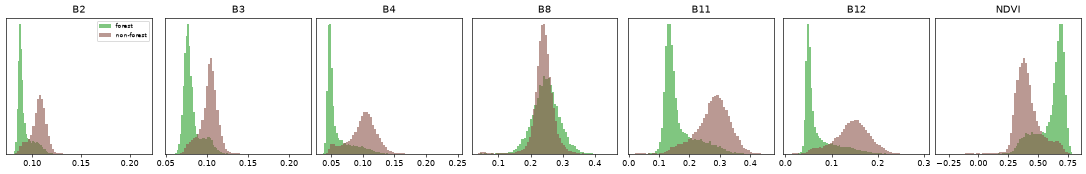

In [4]:
# Per-band reflectance for forest vs non-forest on train tiles: is the signal separable?
Xs, ys = baselines.sample_pixels([img[Y1], img[Y2]], [forest[Y1], forest[Y2]], experiment.windows(TILES["train"]), 50000, SEED)
fig, ax = plt.subplots(1, 7, figsize=(18, 2.8), layout="constrained")
for i, band in enumerate(viz.BANDS):
    for cls, col in ((1, "tab:green"), (0, "tab:brown")):
        ax[i].hist(Xs[ys == cls, i] / 1e4, bins=60, alpha=0.6, color=col, density=True, label=["non-forest", "forest"][cls])
    ax[i].set_title(band); ax[i].set_yticks([])
nd = (Xs[:, 3] - Xs[:, 2]) / (Xs[:, 3] + Xs[:, 2])
for cls, col in ((1, "tab:green"), (0, "tab:brown")):
    ax[6].hist(nd[ys == cls], bins=60, alpha=0.6, color=col, density=True)
ax[6].set_title("NDVI"); ax[6].set_yticks([]); ax[0].legend(fontsize=7)
fig.savefig(FIGS / "band_histograms.png", dpi=70)

In [5]:
# PRODES (INPE) yearly deforestation polygons: independent of Hansen, used in sections 7 and 8.
try:
    fc = prodes.load_or_fetch(cfg.aoi.bbox, Path(cfg.paths.raw) / "prodes_yearly_deforestation.geojson")
    prodes_loss = prodes.rasterize_years(fc, range(Y1 + 1, Y2 + 1), B.valid.shape, B.transform, cfg.aoi.crs)
    print(len(fc["features"]), "PRODES polygons;", f"{Y1 + 1}-{Y2}:",
          round(experiment.metrics.area_ha(prodes_loss, B.transform), 1), "ha in AOI")
except Exception as e:  # no fallback: section 8 states the limitation instead
    prodes_loss = None
    print("PRODES unavailable:", repr(e))

73 PRODES polygons; 2019-2022: 395.4 ha in AOI


## 2. Baselines

**NDVI threshold**: forest if NDVI ≥ t, with t chosen to maximise forest IoU on the **val** tiles (both years).
**Random forest**: per-pixel classifier on the 6 raw band values, trained on random pixels from the **train** tiles (both years).

NDVI threshold chosen on val: 0.52 (val IoU 0.5681)


random forest: {'pixels': 300000, 'trees': 200, 'fit_s': 9.4, 'feature_importances': {'B2': 0.1153, 'B3': 0.2133, 'B4': 0.0849, 'B8': 0.0671, 'B11': 0.3067, 'B12': 0.2126}}
wrote reports/metrics/train_ndvi.json
wrote reports/metrics/train_random_forest.json


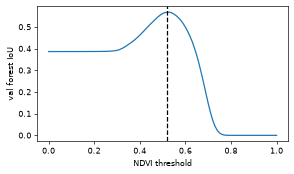

In [6]:
trained = train(["ndvi", "random_forest"])
table = json.loads((MODELS / "ndvi.json").read_text())["val_iou_by_threshold"]
plt.figure(figsize=(5, 3)); plt.plot(*zip(*table)); plt.axvline(trained["ndvi"]["threshold"], ls="--", c="k")
plt.xlabel("NDVI threshold"); plt.ylabel("val forest IoU"); plt.tight_layout()

## 3. U-Net

`segmentation_models_pytorch` U-Net, ResNet-18 encoder, `in_channels=6`, trained on the train tiles of both years
(random flips/rotations), BCE + Dice loss, AdamW, cosine LR, model selection on **val** IoU.
Two runs with identical settings and seed: ImageNet-pretrained encoder vs random init.
Inputs are standardised with per-band mean/std from the train tiles only.

epoch   1 loss 0.7471 val_iou 0.6788 (best 0.6788 @ 1) 2.0s


epoch   2 loss 0.5355 val_iou 0.6900 (best 0.6900 @ 2) 1.1s


epoch   3 loss 0.5092 val_iou 0.6835 (best 0.6900 @ 2) 1.1s


epoch   4 loss 0.5024 val_iou 0.6824 (best 0.6900 @ 2) 1.1s


epoch   5 loss 0.5112 val_iou 0.6905 (best 0.6905 @ 5) 1.1s


epoch   6 loss 0.4939 val_iou 0.6600 (best 0.6905 @ 5) 1.1s


... (55 outputs left out)

epoch  21 loss 0.4663 val_iou 0.6535 (best 0.6920 @ 3) 1.1s


epoch  22 loss 0.4667 val_iou 0.6471 (best 0.6920 @ 3) 1.1s


epoch  23 loss 0.4553 val_iou 0.6838 (best 0.6920 @ 3) 1.1s


early stop at epoch 23
wrote reports/metrics/train_unet_imagenet.json
wrote reports/metrics/train_unet_scratch.json


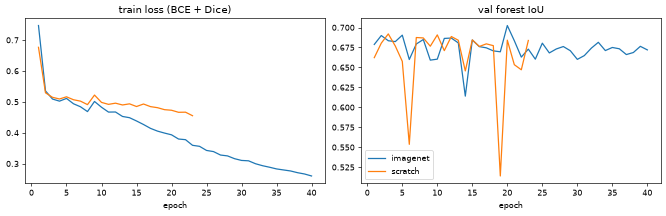

In [7]:
trained.update(train([f"unet_{n}" for n in ucfg.unet.variants]))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for n in ucfg.unet.variants:
    h = trained[f"unet_{n}"]["history"]
    ax[0].plot([r["epoch"] for r in h], [r["train_loss"] for r in h], label=n)
    ax[1].plot([r["epoch"] for r in h], [r["val_iou"] for r in h], label=n)
ax[0].set_title("train loss (BCE + Dice)"); ax[1].set_title("val forest IoU"); ax[1].legend()
for a in ax: a.set_xlabel("epoch")
fig.savefig(FIGS / "training_curves.png", dpi=80)

## 4. Test-tile metrics: forest mask

All four methods predict a forest mask for every val and test tile in both years. Scores pool the pixels of the 9 test tiles × 2 years.
The 95% CI resamples whole test tiles (tile-year pairs) with replacement, so it reflects how few independent test tiles there are.

In [8]:
M = experiment.load_models(ucfg, MODELS, DEVICE)
PRED, _ = experiment.predict_all(M, B, DEVICE)
forest_results = experiment.evaluate_forest(B, PRED, N_BOOT, SEED)
save_json({"task": "forest mask", "split": "test", "n_tiles": len(TILES["test"]), "years": list(B.years),
           "ndvi_threshold": M.ndvi_threshold, "results": forest_results}, "forest_mask_test.json")
pd.DataFrame({m: {**{k: r["pooled"][k] for k in ("iou", "f1", "precision", "recall")},
                  "iou_ci95": "[{:.3f}, {:.3f}]".format(*r["ci95"]["iou"])} for m, r in forest_results.items()}).T

wrote reports/metrics/forest_mask_test.json


,iou,f1,precision,recall,iou_ci95
ndvi,0.700962,0.824195,0.815213,0.833376,"[0.607, 0.770]"
random_forest,0.73903,0.849933,0.894007,0.810001,"[0.649, 0.803]"
unet_imagenet,0.756071,0.861094,0.882535,0.84067,"[0.675, 0.815]"
unet_scratch,0.746239,0.854681,0.869513,0.840347,"[0.664, 0.806]"


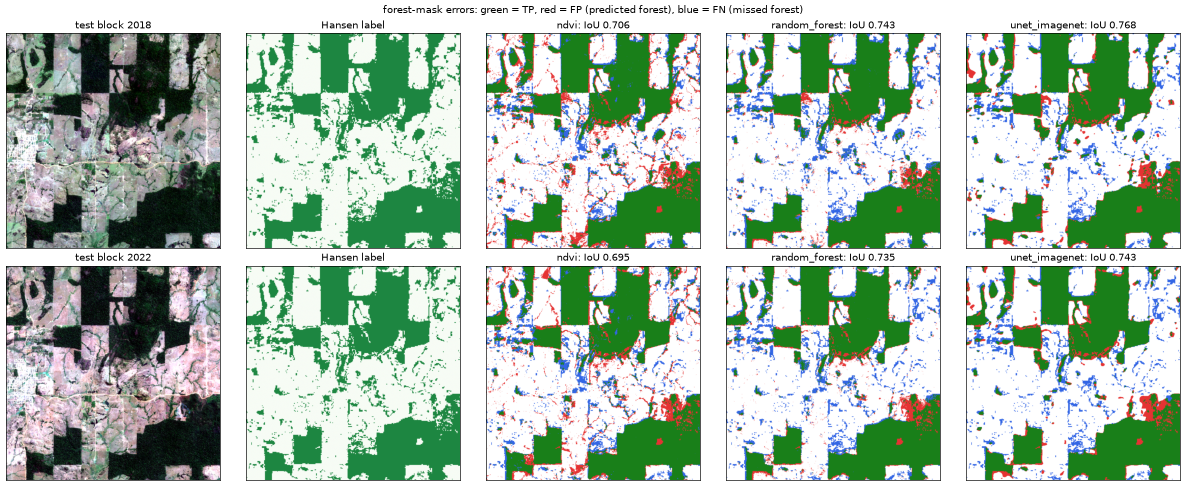

In [9]:
WIN, mosaic = experiment.test_block(B)
show = ["ndvi", "random_forest", "unet_imagenet"]
fig, ax = plt.subplots(2, 2 + len(show), figsize=(4 * (2 + len(show)), 8), layout="constrained")
for i, y in enumerate(B.years):
    ax[i, 0].imshow(viz.rgb(img[y], ref=img[Y1])[WIN]); ax[i, 0].set_title(f"test block {y}")
    ax[i, 1].imshow(forest[y][WIN], cmap="Greens", vmin=0, vmax=1.3); ax[i, 1].set_title("Hansen label")
    for j, m in enumerate(show):
        em = change.error_map(mosaic(PRED[m]["test"][y]), forest[y][WIN])
        ax[i, 2 + j].imshow(np.array([[1, 1, 1], [0.1, 0.5, 0.1], [0.9, 0.2, 0.2], [0.2, 0.4, 0.9]])[em])
        ax[i, 2 + j].set_title(f"{m}: IoU {forest_results[m]['per_year'][y]['iou']:.3f}")
for a in ax.flat: a.set_xticks([]); a.set_yticks([])
fig.suptitle("forest-mask errors: green = TP, red = FP (predicted forest), blue = FN (missed forest)")
fig.savefig(FIGS / "forest_mask_test.png", dpi=70)

## 5. Change detection 2018 → 2022

Loss is compared with Hansen loss. **Hansen lossyear range: 2019–2022.** Composites span Jun–Sep of each year, and Hansen
loss years are calendar years, so 2019–2022 is the closest match. It also equals forest(2018) AND NOT forest(2022) under the
label rule. Caveats: loss in Oct–Dec 2018 falls outside the window, and loss in Oct–Dec 2022 is counted although it happened
after the 2022 composite.

Two ways to get a loss map:

* **Differencing**: predicted forest 2018 AND NOT predicted forest 2022, using the four forest-mask methods above.
  Subtracting two independent masks produces speckle along forest edges, so a minimum mapping unit (drop loss blobs smaller
  than *k* pixels) is chosen per method on the **val** tiles from `change.mmu_candidates_px` in `configs/unet.yaml`.
* **Direct change models**: see both years at once (12 bands) and predict loss, trained on Hansen loss.
  * *U-Net (change)*: same architecture, input = 2018 and 2022 stacked, ImageNet-initialised encoder. Loss is ~2% of
    pixels; the Dice term keeps the model from predicting "no loss" everywhere.
  * *Random forest (change)*: per-pixel classifier on the same 12 values, `class_weight=balanced_subsample`.

  The probability threshold and the MMU are chosen together on the **val** tiles.

change random forest: {'pixels': 300000, 'trees': 200, 'max_depth': 20, 'class_weight': 'balanced_subsample', 'fit_s': 11.3}


epoch   1 loss 1.4581 val_iou 0.1520 (best 0.1520 @ 1) 1.5s


epoch   2 loss 1.0247 val_iou 0.1963 (best 0.1963 @ 2) 1.5s


epoch   3 loss 0.7943 val_iou 0.1971 (best 0.1971 @ 3) 1.5s


epoch   4 loss 0.6365 val_iou 0.1929 (best 0.1971 @ 3) 1.5s


epoch   5 loss 0.5623 val_iou 0.3423 (best 0.3423 @ 5) 1.5s


... (55 outputs left out)

epoch  61 loss 0.2757 val_iou 0.3058 (best 0.3578 @ 43) 1.5s


epoch  62 loss 0.2772 val_iou 0.3083 (best 0.3578 @ 43) 1.5s


epoch  63 loss 0.2734 val_iou 0.3153 (best 0.3578 @ 43) 1.5s


early stop at epoch 63
wrote reports/metrics/train_rf_change.json
wrote reports/metrics/train_unet_change.json


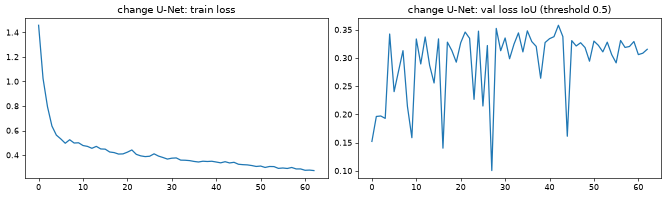

In [10]:
trained.update(train(["rf_change", "unet_change"]))
h = trained["unet_change"]["history"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), layout="constrained")
ax[0].plot([r["train_loss"] for r in h]); ax[0].set_title("change U-Net: train loss")
ax[1].plot([r["val_iou"] for r in h]); ax[1].set_title("change U-Net: val loss IoU (threshold 0.5)")
fig.savefig(FIGS / "training_curves_change.png", dpi=80)

In [11]:
M = experiment.load_models(ucfg, MODELS, DEVICE)
_, PROB = experiment.predict_all(M, B, DEVICE)
change_results, FINAL = experiment.evaluate_change(B, PRED, PROB, C, N_BOOT, SEED)
save_json({"task": "forest loss", "reference": f"Hansen lossyear {Y1 + 1}-{Y2}", "split": "test",
           "selection": "MMU (and threshold for direct models) chosen on val tiles", "results": change_results}, "change_test.json")
(MODELS / "deploy.json").write_text(json.dumps(experiment.deploy_spec(change_results, ucfg), indent=2))
pd.DataFrame({m: {"approach": r["approach"], "threshold": r.get("threshold"), "mmu_px": r["mmu_px"], "val_iou": r["val_iou"],
                  **{k: r["pooled"][k] for k in ("iou", "f1", "precision", "recall")},
                  "f1_ci95": "[{:.3f}, {:.3f}]".format(*r["ci95"]["f1"])} for m, r in change_results.items()}).T

wrote reports/metrics/change_test.json


,approach,threshold,mmu_px,val_iou,iou,f1,precision,recall,f1_ci95
ndvi,differencing,None,100,0.061544,0.228677,0.372233,0.342621,0.407449,"[0.132, 0.507]"
random_forest,differencing,None,50,0.194253,0.377262,0.547843,0.568743,0.528425,"[0.327, 0.632]"
unet_imagenet,differencing,None,50,0.099185,0.28008,0.437597,0.343375,0.603082,"[0.190, 0.564]"
unet_scratch,differencing,None,100,0.140706,0.22008,0.360764,0.319992,0.413442,"[0.108, 0.491]"
rf_change,direct,0.2,100,0.308921,0.410706,0.582271,0.489113,0.719264,"[0.361, 0.685]"
unet_change,direct,0.7,25,0.360458,0.451152,0.621785,0.594272,0.651969,"[0.375, 0.719]"


loss method with the best val IoU (used for the error map and error analysis): unet_change


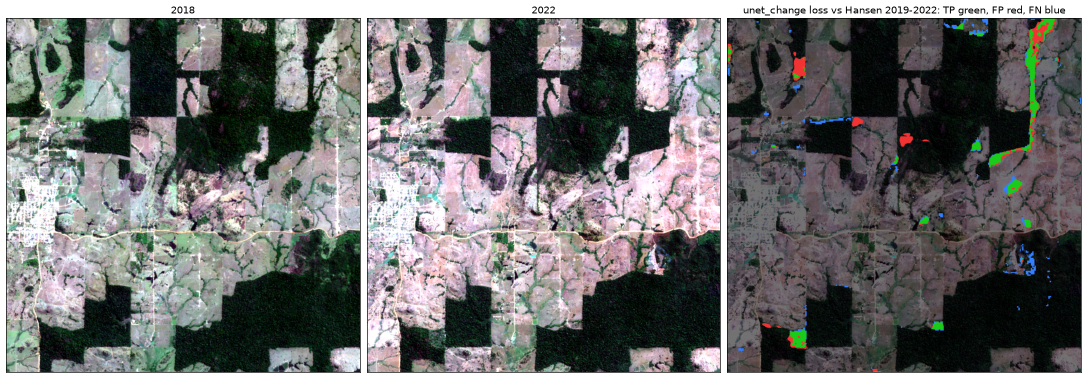

In [12]:
BEST = max(change_results, key=lambda m: change_results[m]["val_iou"])  # chosen on val, not test
pred_loss, true_loss = mosaic(FINAL[BEST]["test"]), B.hloss[WIN]
em = change.error_map(pred_loss, true_loss)
pal = np.array([[0, 0, 0], [0.1, 0.8, 0.1], [0.95, 0.2, 0.2], [0.2, 0.5, 1.0]])
rgb1, rgb2 = viz.rgb(img[Y1], ref=img[Y1])[WIN], viz.rgb(img[Y2], ref=img[Y1])[WIN]
fig, ax = plt.subplots(1, 3, figsize=(18, 6.4), layout="constrained")
ax[0].imshow(rgb1); ax[0].set_title(f"{Y1}")
ax[1].imshow(rgb2); ax[1].set_title(f"{Y2}")
over = rgb2 * 0.45
over[em > 0] = pal[em[em > 0]]
ax[2].imshow(over); ax[2].set_title(f"{BEST} loss vs Hansen {Y1 + 1}-{Y2}: TP green, FP red, FN blue")
for a in ax: a.set_xticks([]); a.set_yticks([])
fig.savefig(FIGS / "change_error_map.png", dpi=70)
print("loss method with the best val IoU (used for the error map and error analysis):", BEST)

## 6. Area lost (test tiles)

Each 10 m pixel is 0.01 ha (computed from the raster transform).

In [13]:
area = experiment.area_summary(B, FINAL, prodes_loss)
save_json(area, "area_test.json")
pd.Series({k: v for k, v in area.items() if k.endswith("_ha")}).round(2).to_frame("hectares (test tiles)")

wrote reports/metrics/area_test.json


,hectares (test tiles)
test_area_ha,5898.24
pixel_area_ha,0.01
hansen_ha,116.80
ndvi_ha,138.90
random_forest_ha,108.52
unet_imagenet_ha,205.14
unet_scratch_ha,150.91
rf_change_ha,171.76
unet_change_ha,128.14
prodes_ha,10.80


## 7. Error analysis

Each loss error pixel of the loss method with the best **val** IoU gets one category, in priority order,
using only the Hansen layers (and PRODES when available), see `change.categorize_fp` / `categorize_fn`:

* **FP** (model loss, no Hansen 2019–2022 loss): *PRODES 2019–22 deforestation* → *Hansen loss 2023+* (model sees a
  clearing Hansen dates later) → *Hansen loss ≤2018* → *canopy < threshold in 2000* (outside the label definition,
  e.g. secondary vegetation) → *forest edge* (≤2 px from the Hansen 2018 forest boundary) → *stable forest interior*.
* **FN** (Hansen loss the model missed): for differencing methods, *model: non-forest already in 2018* or *model: still
  forest in 2022*; for direct models, *small Hansen patch* (< 50 px = 0.5 ha) or *large patch*. Each is split into
  *edge* (≤2 px from the Hansen loss patch boundary) vs *interior*.

Then the 10 largest FP and FN blobs are shown.

In [14]:
fp, fn = em == change.FP, em == change.FN
fp_cat = change.categorize_fp(fp, B.lossyear[WIN], B.treecover[WIN], cfg.labels.treecover_threshold, forest[Y1][WIN],
                              Y1, Y2, None if prodes_loss is None else prodes_loss[WIN])
approach = change_results[BEST]["approach"]
pf = (mosaic(PRED[BEST]["test"][Y1]), mosaic(PRED[BEST]["test"][Y2])) if approach == "differencing" else (None, None)
fn_cat = change.categorize_fn(fn, true_loss, approach, *pf)
err = {"method": BEST, "fp_pixels": int(fp.sum()), "fn_pixels": int(fn.sum()),
       "fp_categories": change.summarise_categories(fp_cat, fp), "fn_categories": change.summarise_categories(fn_cat, fn)}
pd.concat({"FP": pd.DataFrame(err["fp_categories"]).T, "FN": pd.DataFrame(err["fn_categories"]).T})

pixels   share
FP stable forest interior              2334.0  0.4489
   Hansen loss <=2018                   749.0  0.1441
   forest edge (<=2 px)                 723.0  0.1391
   canopy2000 < threshold               675.0  0.1298
   Hansen loss 2023+                    384.0  0.0739
   PRODES 2019-22 deforestation         334.0  0.0642
FN large Hansen patch, edge            2847.0  0.7004
   small Hansen patch (<0.5 ha), edge   989.0  0.2433
   large Hansen patch, interior         229.0  0.0563

wrote reports/metrics/error_analysis.json


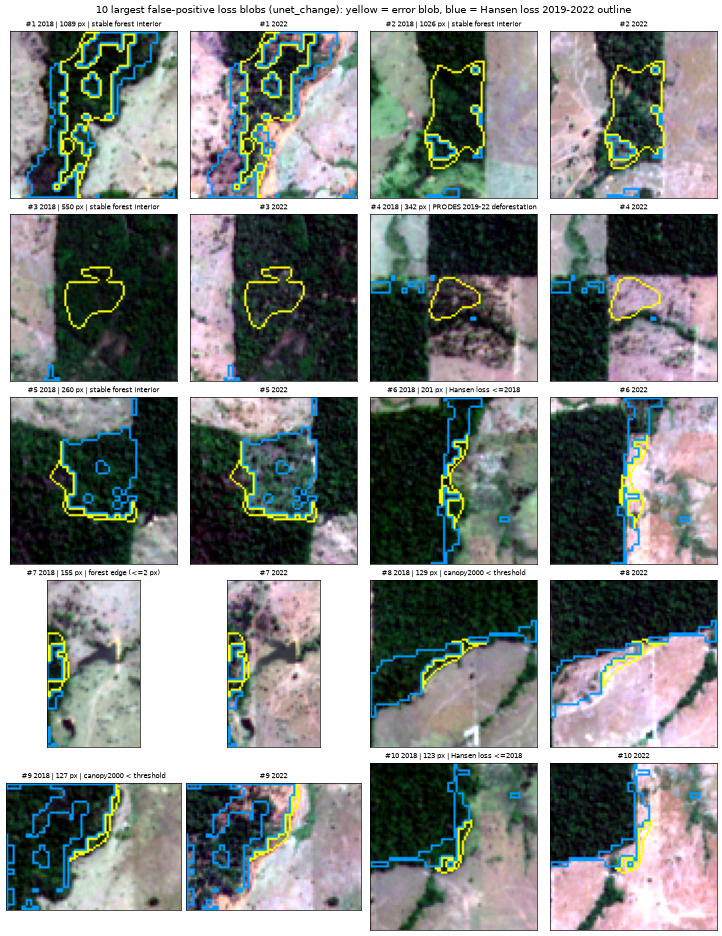

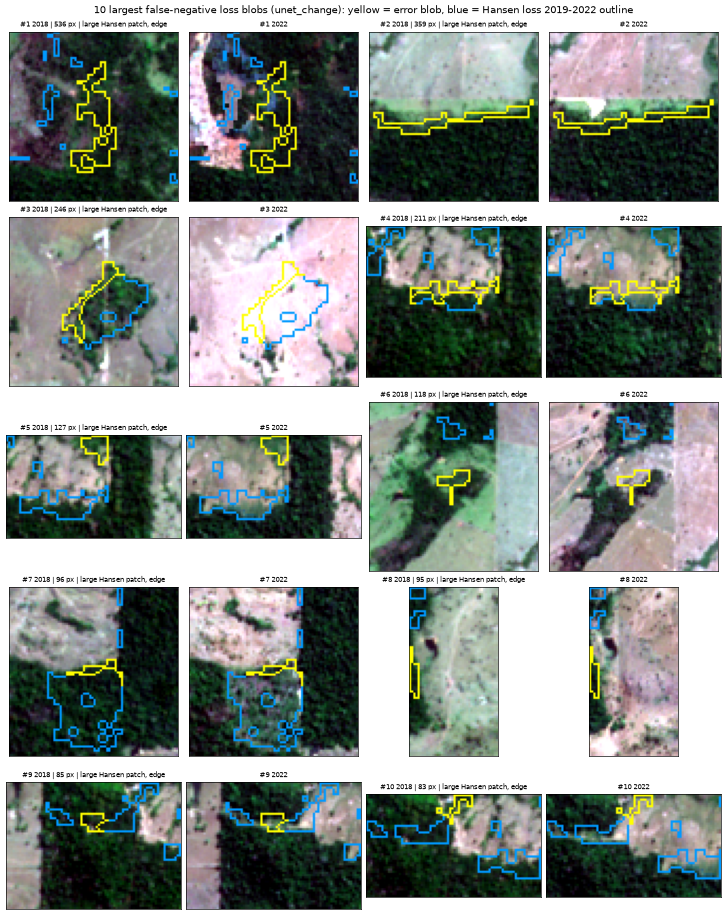

In [15]:
r0, c0 = WIN[0].start, WIN[1].start
for kind, mask, cat in (("fp", fp, fp_cat), ("fn", fn, fn_cat)):
    label = "false-positive" if kind == "fp" else "false-negative"
    fig, info = viz.error_gallery(mask, cat, true_loss, rgb1, rgb2, B.years, f"10 largest {label} loss blobs ({BEST})")
    fig.savefig(FIGS / f"errors_{kind}.png", dpi=70)
    err[f"{kind}_gallery"] = [{**i, "row": i["row"] + r0, "col": i["col"] + c0} for i in info]
save_json(err, "error_analysis.json")

**Visual reading of the galleries** for the direct change U-Net. These are my interpretation of the 20 thumbnails above: the pixel shares in the table are computed, these notes are not.

*False positives*, where the model says loss and Hansen says no loss 2019–2022:
- **Boundary slivers** along Hansen loss patches and forest edges (#5–#10). Hansen's 30 m pixels and the 10 m imagery disagree by 1–3 pixels. These are much thinner than with differencing.
- **Degraded or burned forest around a clearing** (#1), and a patch that **PRODES maps as 2019–2022 deforestation** (#4). In both the canopy looks thinned in 2022. The model may be right and the Hansen label incomplete.
- **Real false alarms inside intact forest** (#2, #3). Both years look like closed forest.

*False negatives*, where Hansen says loss and the model misses it:
- **Edge strips of Hansen loss patches** (#2, #4, #5, #7–#10), with little visible change at 10 m. This matches the computed category shares (mostly "edge").
- **Partly detected clearings** (#3) and **degraded rather than cleared forest** (#1).
- A narrow tree line in pasture (#6).

## 8. Independent check (PRODES) and limitations

Labels come from Hansen, so agreement with Hansen is partly circular: a model that copies Hansen well scores well even where
Hansen is wrong. [PRODES](https://terrabrasilis.dpi.inpe.br/) (INPE) is an independent, visually interpreted Landsat
product. It maps **clear-cut of primary forest only**, with a minimum polygon of 6.25 ha (1 ha in recent years), and masks
anything deforested earlier. So PRODES is a stricter definition of loss than Hansen: expect high recall against PRODES and
lower precision. PRODES years 2019–2022 cover about Aug 2018 – Jul 2022, which matches the composite dates well.

In [16]:
if prodes_loss is None:
    print("PRODES not available in this run; the comparison is skipped and stated as a limitation.")
else:
    prodes_results = experiment.prodes_summary(B, FINAL, prodes_loss)
    save_json(prodes_results, "prodes_test.json")
    display(pd.DataFrame({k: v for k, v in prodes_results.items() if isinstance(v, dict)}).T[["iou", "f1", "precision", "recall"]].round(4))

wrote reports/metrics/prodes_test.json


,iou,f1,precision,recall
hansen_vs_prodes,0.0109,0.0215,0.0117,0.1269
hansen_vs_prodes_whole_aoi,0.1612,0.2777,0.1844,0.5615
ndvi_vs_prodes,0.0366,0.0707,0.0381,0.4898
random_forest_vs_prodes,0.0474,0.0905,0.0498,0.5000
unet_imagenet_vs_prodes,0.0133,0.0262,0.0138,0.2620
unet_scratch_vs_prodes,0.0387,0.0746,0.0400,0.5583
rf_change_vs_prodes,0.0359,0.0692,0.0368,0.5852
unet_change_vs_prodes,0.0321,0.0622,0.0337,0.4000


**Limitations**

* Labels are Hansen-derived: test scores measure agreement with Hansen, which has its own errors (see section 7).
* 9 test tiles from one 22 km × 22 km area: the CIs are wide and the numbers say nothing about other regions.
* L1C top-of-atmosphere reflectance (no atmospheric correction); both years are processed identically.
* Hansen loss years are calendar years while composites are Jun–Sep, so loss timing at the window edges is ambiguous.
* The forest definition (≥30% canopy in 2000, no later loss) ignores regrowth after 2000.
* Remaining loss errors are mostly 1–3 pixel boundary disagreements with Hansen's 30 m grid, plus degraded forest.